# Clio-Infra at historical borders — what is there

A survey of the DataverseNL deposits, the companion to `notebooks/clio`'s
`inventory.ipynb`: what is filed, how the workbooks are laid out, what their two
border schemes actually carry, what the working papers provide, and how the
stored series stand to the main site.

**Input**, all under `notebooks/clio_historical/data/` (gitignored):
`raw/<folder>/` — the deposits, downloaded by hand — plus `datasets.json` (every
indicator's DOI) and `documentation.yaml` (the working papers). **Output:**
`inventory.json`, written by `utils.inventory.build()` below. No network.

In [1]:
import sys
sys.path.append("../")          # notebooks/clio_historical/, for utils

import json
from pathlib import Path
import numpy
import pandas
from matplotlib import pyplot, colors

from lib import config
from utils import accept, documentation, inventory
from utils import break_gaps, to_arrays, stamp_source
from utils import historical_series as hs

pyplot.style.use(config.glyfish_style)
pandas.set_option("display.max_rows", 100)
pandas.set_option("display.width", 160)

documentation.build()                     # the papers, in case more were filed
measured = inventory.build()
unfiled = json.loads((accept.DATA_DIR / inventory.INVENTORY).read_text())["unfiled"]
table = pandas.DataFrame([{"indicator": v["name"], "category": v["category"], **v}
                          for v in measured.values()]).drop(columns="name")
print(f"{len(measured)} of {len(measured) + len(unfiled)} indicators filed")

76 of 86 indicators filed


## What is filed

Every deposit but one carries a working paper. Twenty-four are legacy Word 97
`.doc` rather than `.docx` — `textutil` converts them — and globbing only
`*.docx` once recorded all twenty-four as having none. The exception is
Biodiversity, whose paper is a PDF and is not read.

In [2]:
print(f"with a working paper : {table.paper.sum()}")
print(f"workbook only        : {(~table.paper).sum()}")
print(f"not filed            : {len(unfiled)}")
for name in unfiled:
    print(f"  {name}")

with a working paper : 75
workbook only        : 1
not filed            : 10
  Cattle per Capita
  Cropland per Capita
  Goats per Capita
  Number of Labour Disputes
  Pasture per Capita
  Pigs per Capita
  Regulation of Participation (PARREG)
  Sheep per Capita
  Total CO2 Emissions
  Total SO2 Emissions


## One workbook layout

Every deposit is the same shape: the indicator on row 1, the unit on row 2, the
`Webmapper code` header on row 3. Eleven leave the unit blank, and since Excel
omits an empty row entirely, reading rows in document order closed the gap and
made those look like a layout of their own — as did one deposit's second,
accidental copy of its workbook.

In [3]:
table.layout.value_counts().rename("indicators").to_frame()

,indicators
layout,
"title, unit, header",76


## The two border schemes

The reason this source exists is its **GeaCron** rows — one per polity per
historical border period, holding the values inside that period. Its **CShapes**
rows are post-1946 states whose series reach back before 1946: the main site's
data in another layout, already stored as `clio`.

Every workbook lists the same 1,166 GeaCron periods but two — one lists 1,412,
one none at all. Counting what they carry:

In [4]:
g = pandas.json_normalize(table.geacron.tolist()).add_prefix("geacron_")
c = pandas.json_normalize(table.cshapes.tolist()).add_prefix("cshapes_")
schemes = pandas.concat([table[["indicator", "category"]], g, c], axis=1)
print(f"GeaCron rows listed    : {schemes.geacron_rows.sum():,}")
print(f"  with any value       : {schemes.geacron_rows_with_values.sum():,}, "
      f"in {(schemes.geacron_rows_with_values > 0).sum()} indicators")
print(f"  observations         : {schemes.geacron_observations.sum():,}")
print(f"CShapes rows with value: {schemes.cshapes_rows_with_values.sum():,}")
print(f"  observations         : {schemes.cshapes_observations.sum():,}\n")
(schemes[schemes.geacron_rows_with_values > 0]
 [["indicator", "geacron_rows_with_values", "geacron_observations", "geacron_start", "geacron_end"]]
 .sort_values("geacron_observations", ascending=False).set_index("indicator"))

GeaCron rows listed    : 87,696
  with any value       : 416, in 4 indicators
  observations         : 11,376
CShapes rows with value: 9,184
  observations         : 808,352



,geacron_rows_with_values,geacron_observations,geacron_start,geacron_end
indicator,,,,
Exchange Rates to UK Pound,180,5685,1500.0,1945.0
Number of Days Lost in Labour Disputes,127,3423,1946.0,2012.0
Labourers Real Wage,102,2268,1820.0,1945.0
Working week in manufacturing,7,0,NaN,NaN


Three indicators, then. Working week's seven rows
carry no observations of their own: they are dependencies with no modern state
to file under — Bermuda, Gibraltar, Guam, Hong Kong, Polynesia, Puerto
Rico, Réunion — so their post-1946 values sit on a border period that ended in
1945. The builder drops values outside their row's period, as this count does.


Coverage by decade, which is what the deposits are good for at a glance: each
cell counts the rows carrying any value in that decade, and the row's span is
the indicator's time range. Nearly all of it is CShapes — modern states holding
the main site's data — so a marked (●) indicator is one of the four whose
historical-border rows carry values of their own.

Text(0.5, 1.0, 'DataverseNL deposits: coverage by indicator and decade')

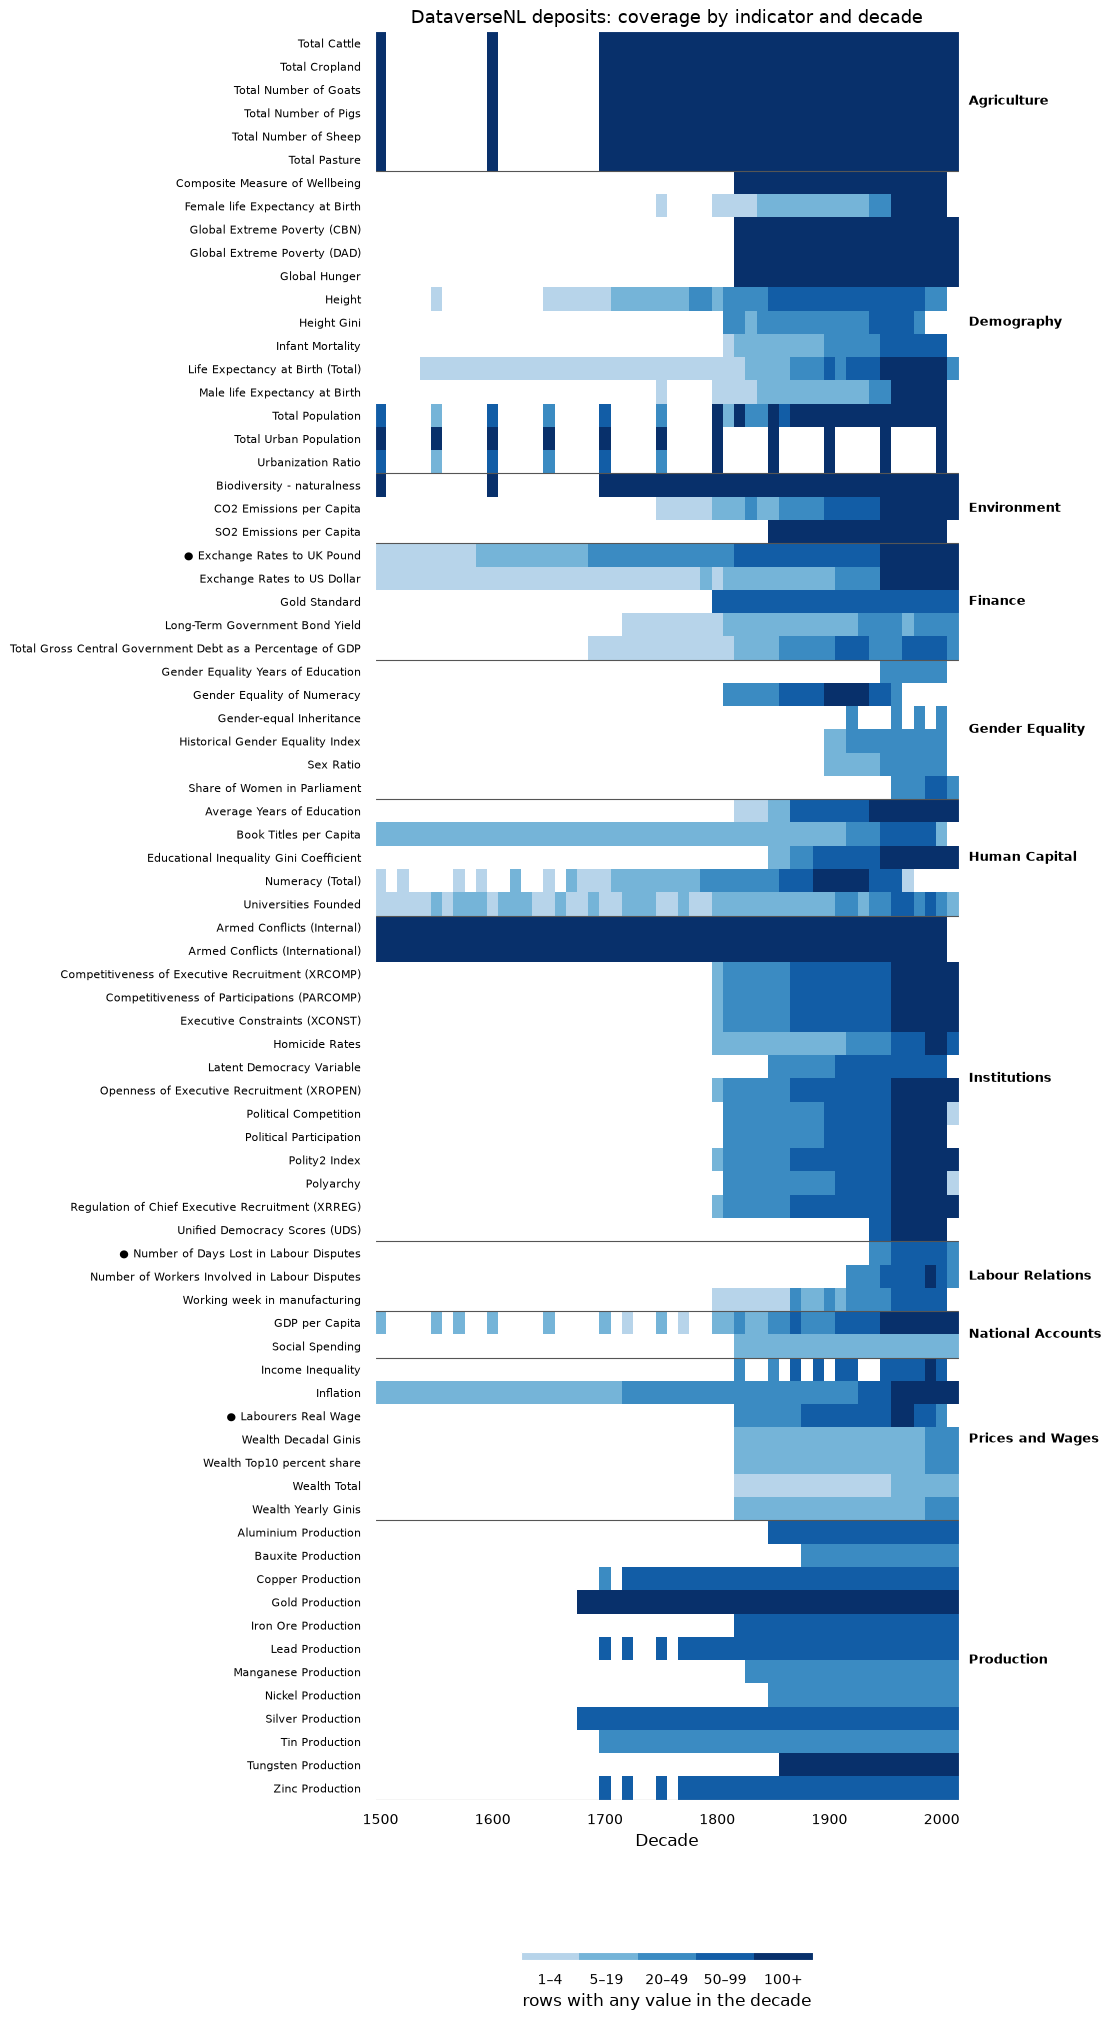

In [5]:
decades = numpy.arange(1500, 2020, 10)
rows = table.sort_values(["category", "indicator"]).reset_index(drop=True)
keys = [next(k for k, v in measured.items() if v["name"] == name) for name in rows.indicator]

grid = numpy.array([[sum(measured[k][s]["rows_by_decade"].get(str(d), 0) for s in ("cshapes", "geacron"))
                     for d in decades] for k in keys], dtype=float)
grid[grid == 0] = numpy.nan                        # empty decades stay white, not dark

bounds = [1, 5, 20, 50, 100, 250]
cmap = colors.ListedColormap(pyplot.get_cmap("Blues")(numpy.linspace(0.3, 1.0, len(bounds) - 1)))
cmap.set_bad("white")

figure, axis = pyplot.subplots(figsize=(11, 20), layout="constrained")
image = axis.pcolormesh(decades, numpy.arange(len(rows)), grid,
                        cmap=cmap, norm=colors.BoundaryNorm(bounds, cmap.N), shading="nearest")
axis.grid(False)
axis.set_xlabel("Decade")
axis.set_yticks(numpy.arange(len(rows)))
axis.set_yticklabels([("● " if measured[k]["geacron"]["observations"] else "") + name
                      for k, name in zip(keys, rows.indicator)], fontsize=8)
axis.invert_yaxis()
start = 0
for category, group in rows.groupby("category", sort=False):
    end = start + len(group)
    axis.axhline(end - 0.5, color="#555555", lw=0.8)
    axis.text(decades[-1] + 14, (start + end - 1) / 2, category, va="center",
              fontsize=9, fontweight="bold")
    start = end
bar = figure.colorbar(image, ax=axis, orientation="horizontal", shrink=0.5, aspect=40,
                      ticks=[3, 12, 35, 75, 175])
bar.ax.set_xticklabels(["1–4", "5–19", "20–49", "50–99", "100+"])
bar.set_label("rows with any value in the decade")
axis.set_title("DataverseNL deposits: coverage by indicator and decade", fontsize=13)

## What the working papers provide

The papers are where this source earns its keep: units, documentation, and a
data-quality grading the main site never states — when the paper fills it in.

In [6]:
papers = table[table.paper]
unit = numpy.where(table.workbook_unit.notna(), "workbook row 2",
                   numpy.where(table.paper_unit.notna(), "working paper", "none"))
print("unit comes from:")
print(pandas.Series(unit).value_counts().to_string(), "\n")
print(f"papers {len(papers)}: data quality assessed {papers.quality_stated.sum()}, "
      f"grades listed but none chosen {(~papers.quality_stated).sum()}")
print(f"  full working-paper text: {(papers.text_chars > 0).sum()}; "
      f"abstracts taken from Wikipedia: {(papers.abstract_source == 'wikipedia').sum()}; "
      f"superseded editions kept: {papers.superseded.sum()}")
print(f"  author's version: {papers.paper_version.value_counts(dropna=False).to_dict()}")

unit comes from:
workbook row 2    65
working paper     10
none               1 

papers 75: data quality assessed 53, grades listed but none chosen 22
  full working-paper text: 48; abstracts taken from Wikipedia: 4; superseded editions kept: 2
  author's version: {'1': 69, '2': 6}


## How the stored series stand to the main site

Every stored series was compared with the main site's, value by value, allowing
for the main site's rounding to seven significant figures.

In [7]:
stored = pandas.DataFrame([{"indicator": v["name"], **v["stored"]}
                           for v in measured.values() if v["stored"]]).fillna(0).set_index("indicator")
stored = stored.reindex(columns=["same", "successor", "differs", "new"], fill_value=0).astype(int)
stored.loc["total"] = stored.sum()
stored

,same,successor,differs,new
indicator,,,,
Exchange Rates to UK Pound,150,26,0,0
Labourers Real Wage,82,12,1,3
Number of Days Lost in Labour Disputes,117,0,0,0
total,349,38,1,3


Each relation drawn, one panel apiece. A solid line is the main site's
modern-border series; a dashed line is a border-period series from this source.
Where the dashed line sits on the solid one, the deposit is carrying the main
site's numbers under an older name.


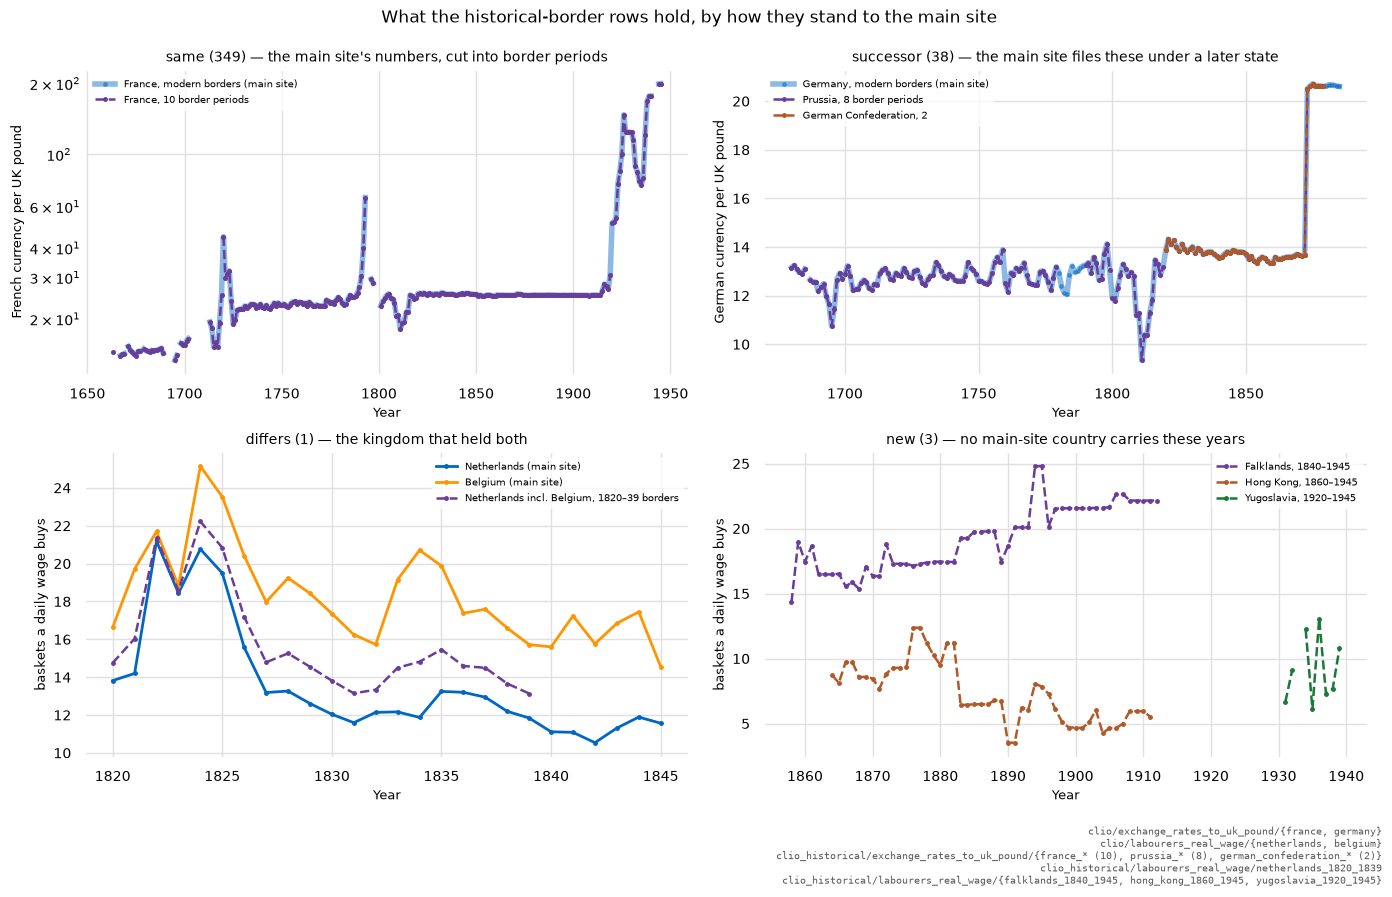

In [8]:
CLIO = hs.CLIO_DATA / "timeseries" / "clio.jsonl"
PURPLE, BROWN, GREEN = "#6a3d9a", "#b15928", "#1b7837"

def load(path, ids=(), prefixes=()):
    """The series as loaded, straight from the .jsonl the database was filled from."""
    out = {}
    for line in Path(path).open():
        record = json.loads(line)
        if record["native_id"] in ids or any(record["native_id"].startswith(p) for p in prefixes):
            out[record["native_id"]] = record
    return out

E, W = "clio_historical/exchange_rates_to_uk_pound/", "clio_historical/labourers_real_wage/"
hist = load(accept.DATA_DIR / "timeseries" / "clio_historical.jsonl",
            prefixes=(E + "france_", E + "prussia_", E + "german_confederation_",
                      W + "netherlands_1820_1839", W + "falklands", W + "hong_kong", W + "yugoslavia"))
site = load(CLIO, ids={"clio/exchange_rates_to_uk_pound/france", "clio/exchange_rates_to_uk_pound/germany",
                       "clio/labourers_real_wage/netherlands", "clio/labourers_real_wage/belgium"})
periods = lambda prefix: [hist[k] for k in sorted(hist) if k.startswith(prefix)]

def panel(axis, window, solid=(), dashed=(), log=False, title="", ylabel=""):
    lo, hi = window
    def cut(record):
        years, values = to_arrays(record)
        inside = (years >= lo) & (years <= hi)
        return break_gaps(years[inside], values[inside])          # (x, y)
    for record, label, kw in solid:
        axis.plot(*cut(record), "-", marker="o", markersize=2.5, label=label, **kw)
    for records, label, color in dashed:
        for i, record in enumerate(sorted(records, key=lambda r: r["observation_start"])):
            axis.plot(*cut(record), "--", lw=1.8, marker="o", markersize=2.5, color=color,
                      label=label if i == 0 else None)           # one legend entry per polity
    axis.set_yscale("log" if log else "linear")
    axis.set_title(title, fontsize=10)
    axis.set_ylabel(ylabel, fontsize=9)
    axis.set_xlabel("Year", fontsize=9)
    axis.legend(fontsize=7.5, loc="best")

figure, axes = pyplot.subplots(2, 2, figsize=(14, 9))
wide = {"lw": 4, "alpha": 0.45}                    # the main site, wide enough to show through
france, prussia, confederation = (periods(E + p) for p in ("france_", "prussia_", "german_confederation_"))

panel(axes[0][0], (1660, 1945), log=True,
      solid=[(site["clio/exchange_rates_to_uk_pound/france"], "France, modern borders (main site)", wide)],
      dashed=[(france, f"France, {len(france)} border periods", PURPLE)],
      title=f"same ({stored.loc['total', 'same']}) — the main site's numbers, cut into border periods",
      ylabel="French currency per UK pound")

panel(axes[0][1], (1680, 1885),
      solid=[(site["clio/exchange_rates_to_uk_pound/germany"], "Germany, modern borders (main site)", wide)],
      dashed=[(prussia, f"Prussia, {len(prussia)} border periods", PURPLE),
              (confederation, f"German Confederation, {len(confederation)}", BROWN)],
      title=f"successor ({stored.loc['total', 'successor']}) — the main site files these under a later state",
      ylabel="German currency per UK pound")

panel(axes[1][0], (1815, 1845),
      solid=[(site["clio/labourers_real_wage/netherlands"], "Netherlands (main site)", {"lw": 2}),
             (site["clio/labourers_real_wage/belgium"], "Belgium (main site)", {"lw": 2})],
      dashed=[([hist[W + "netherlands_1820_1839"]], "Netherlands incl. Belgium, 1820–39 borders", PURPLE)],
      title=f"differs ({stored.loc['total', 'differs']}) — the kingdom that held both",
      ylabel="baskets a daily wage buys")

panel(axes[1][1], (1850, 1945),
      dashed=[(periods(W + "falklands"), "Falklands, 1840–1945", PURPLE),
              (periods(W + "hong_kong"), "Hong Kong, 1860–1945", BROWN),
              (periods(W + "yugoslavia"), "Yugoslavia, 1920–1945", GREEN)],
      title=f"new ({stored.loc['total', 'new']}) — no main-site country carries these years",
      ylabel="baskets a daily wage buys")

figure.suptitle("What the historical-border rows hold, by how they stand to the main site", fontsize=12)
figure.tight_layout()
stamp_source(*({"native_id": s} for s in (
    "clio/exchange_rates_to_uk_pound/{france, germany}",
    "clio/labourers_real_wage/{netherlands, belgium}",
    f"{E}{{france_* ({len(france)}), prussia_* ({len(prussia)}), german_confederation_* ({len(confederation)})}}",
    f"{W}netherlands_1820_1839",
    f"{W}{{falklands_1840_1945, hong_kong_1860_1945, yugoslavia_1920_1945}}")), figure=figure)
# the stamp reserves a line's height apiece, sized for a single-panel figure;
# on a tall one that leaves a band of white, so give the panels the room back
figure.subplots_adjust(bottom=0.15)


Numerically, then, the deposits are the main site's data relabelled by the
borders in force: 349 series identical, 38 filed there under a modern successor,
one that differs because its borders do (the Netherlands with Belgium,
1820–39), and three the main site lacks. What this source adds is that label and,
more than the data, the working papers — whose units and documentation now feed
`clio`.